In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np


In [2]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95],
    "Assignment_Marks": [10, 12, 15, 16, 18, 20, 22, 24, 26, 28],
    "Marks": [35, 40, 45, 50, 55, 60, 65, 70, 80, 90]
}


In [3]:
df = pd.DataFrame(data)

print("Dataset:")
print(df)


Dataset:
   Study_Hours  Attendance  Assignment_Marks  Marks
0            1          50                10     35
1            2          55                12     40
2            3          60                15     45
3            4          65                16     50
4            5          70                18     55
5            6          75                20     60
6            7          80                22     65
7            8          85                24     70
8            9          90                26     80
9           10          95                28     90


In [4]:
X_simple = df[["Study_Hours"]]

In [5]:
X_multiple = df[["Study_Hours", "Attendance", "Assignment_Marks"]]

In [7]:
y = df["Marks"]

In [8]:
X_train_s, X_test_s, y_train, y_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

X_train_m, X_test_m, _, _ = train_test_split(X_multiple, y, test_size=0.2, random_state=42)


In [9]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)


In [10]:
print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))



--- Simple Linear Regression ---
Intercept: 26.98275862068965
Coefficient: 5.775862068965518
R2 Score: 0.9959776307966706
RMSE: 1.2684430146174346


In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)


In [12]:
print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))



--- Multiple Linear Regression ---
Intercept: -15.294943820224631
Coefficients: [0.15449438 0.77247191 0.8988764 ]
R2 Score: 0.9950517216891808
RMSE: 1.4068799964203373


In [13]:
new_student_simple = pd.DataFrame({"Study_Hours": [6]})

new_student_multiple = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [80],
    "Assignment_Marks": [22]
})


In [14]:
print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])



Predicted marks using Simple Regression: 61.63793103448276
Predicted marks using Multiple Regression: 67.2050561797753


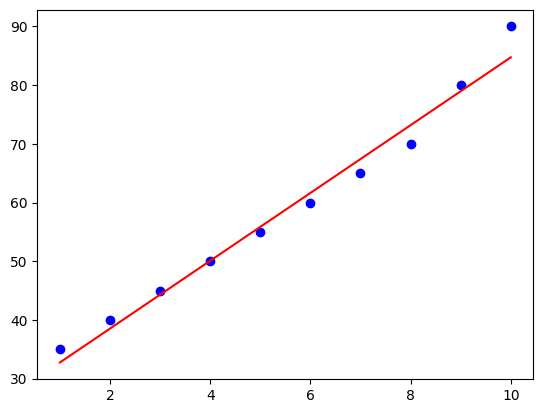

In [15]:
plt.scatter(df["Study_Hours"], df["Marks"],
            color="blue", label="Actual Marks")

plt.plot(
    df["Study_Hours"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)


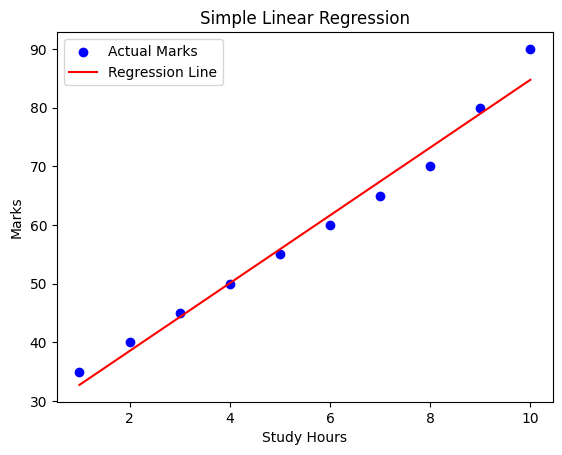

In [17]:
plt.scatter(df["Study_Hours"], df["Marks"],
            color="blue", label="Actual Marks")

plt.plot(
    df["Study_Hours"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()
